In [2]:
# DermAI Diagnostics
## Skin Cancer Intelligence Platform

### Exploratory Data Analysis (EDA)

# Objective**

# Understand the skin cancer dataset before preprocessing and machine learning.

# This notebook covers:

# Dataset overview
# Data quality assessment
# Missing values
# Data types
# Target distribution
# Univariate analysis
# Bivariate analysis
# Correlation analysis
# Key business insights

### STEP 1 — Import Libraries

In [3]:

import os
import warnings

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

%matplotlib inline

sns.set_theme(style="whitegrid", font_scale=1.1)
 
# Load Dataset

DATA_PATH = os.path.join(
    "..",
    "data",
    "raw",
    "dermai_ml_ready.csv"
)

df = pd.read_csv(DATA_PATH)

df.head()

,patient_id,age,age_group,gender,smoke,drink,pesticide,skin_cancer_history,cancer_history,has_piped_water,...,lesion_size_category,itch,grew,hurt,changed,bleed,elevation,biopsed,diagnostic,cancerous_flag
0,PAT_100,14,Young Adult,MALE,f,f,f,f,t,f,...,Medium,f,f,f,f,f,f,t,NEV,0
1,PAT_1000,65,Older Adult,MALE,f,f,f,f,f,f,...,Small,f,f,f,f,f,f,f,SEK,0
2,PAT_1006,63,Older Adult,MALE,f,f,f,f,f,f,...,Small,f,f,f,f,f,f,f,ACK,0
3,PAT_1008,64,Older Adult,MALE,f,f,f,f,f,f,...,Small,f,t,f,f,f,t,f,SEK,0
4,PAT_101,59,Older Adult,MALE,t,t,f,f,f,t,...,Large,t,t,t,f,t,t,t,BCC,1


STEP 2 — Dataset Overview

In [4]:
# dataset shape
print(f"Rows: {df.shape[0]}")
print(f"Columns: {df.shape[1]}")

# data info
print(df.info())

# data types
print(df.dtypes)

Rows: 1088
Columns: 29
<class 'pandas.DataFrame'>
RangeIndex: 1088 entries, 0 to 1087
Data columns (total 29 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   patient_id            1088 non-null   str    
 1   age                   1088 non-null   int64  
 2   age_group             1088 non-null   str    
 3   gender                1088 non-null   str    
 4   smoke                 1088 non-null   str    
 5   drink                 1088 non-null   str    
 6   pesticide             1088 non-null   str    
 7   skin_cancer_history   1088 non-null   str    
 8   cancer_history        1088 non-null   str    
 9   has_piped_water       1088 non-null   str    
 10  has_sewage_system     1088 non-null   str    
 11  background_father     1088 non-null   str    
 12  background_mother     1088 non-null   str    
 13  lesion_id             1088 non-null   int64  
 14  fitspatrick           1088 non-null   int64  
 15  region   

In [5]:
# step 2d — Check Numerical vs Categorical Variables

numerical_cols = df.select_dtypes(include=np.number).columns

categorical_cols = df.select_dtypes(exclude=np.number).columns

print("Numerical columns:", len(numerical_cols))
print("Categorical columns:", len(categorical_cols))

Numerical columns: 7
Categorical columns: 22


In [6]:
# step 2e- Statistical Summary
df.describe().T 

,count,mean,std,min,25%,50%,75%,max
age,1088.0,58.568934,16.340580,6.0,49.00,60.0,71.00,94.0
lesion_id,1088.0,1791.945772,1374.516658,6.0,747.75,1373.5,3012.25,4820.0
fitspatrick,1088.0,1.098346,1.290571,0.0,0.00,0.0,2.00,6.0
diameter_1,1088.0,5.193015,7.393119,0.0,0.00,0.0,10.00,70.0
diameter_2,1088.0,3.925551,5.603830,0.0,0.00,0.0,7.00,60.0
avg_diameter,1088.0,4.559283,6.415176,0.0,0.00,0.0,8.00,65.0
cancerous_flag,1088.0,0.318015,0.465919,0.0,0.00,0.0,1.00,1.0


### Dataset Overview Summary

- The dataset contains **1,088 observations** and **29 variables**.

There are:
- 7 numerical variables
- 22 categorical variables

- The variables include patient demographics, lifestyle risk factors, lesion characteristics, and the - - target outcome (cancerous flag). This combination provides both clinical and behavioural information - for predictive modelling.

### STEP 3 — Data Inspection

In [7]:
 # step 3a -  Data  Quality checks

# Missing values
# Duplicate records
# Duplicate identifiers
# Unique values
# Class distribution.

In [8]:
# step 3a(i) Missing Values

missing = (
    df.isna()
      .sum()
      .sort_values(ascending=False)
)

missing = missing[missing > 0]

if len(missing) == 0:
    print("No missing values found.")
else:
    display(missing)

No missing values found.


In [9]:
# step 3a(ii) Duplicate Records

duplicate_rows = df.duplicated().sum()

print(f"Duplicate rows: {duplicate_rows}")

Duplicate rows: 0


In [10]:
# step 3a(iii) Duplicate Patient IDs

duplicate_patients = df["patient_id"].duplicated().sum()

print(f"Duplicate patient IDs: {duplicate_patients}")

Duplicate patient IDs: 0


In [11]:
# step 3a(iv) -  Duplicate Lesion IDs

duplicate_lesions = df["lesion_id"].duplicated().sum()

print(f"Duplicate lesion IDs: {duplicate_lesions}")

Duplicate lesion IDs: 81


In [12]:
# step 3a(v) -  Unique Values per Column

# Identifier columns
# Binary variables
# Low-cardinality categorical variables
# High-cardinality variables

unique_values = (
    df.nunique()
      .sort_values()
      .to_frame("Unique Values")
)

display(unique_values)

,Unique Values
cancerous_flag,2
grew,2
hurt,2
changed,2
bleed,2
elevation,2
has_sewage_system,2
itch,2
has_piped_water,2
skin_cancer_history,2


### STEP 4 - Target distribution

In [13]:

target_counts = df["cancerous_flag"].value_counts().sort_index()
target_percent = (
    df["cancerous_flag"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

print("Counts:")
print(target_counts)

print("\nPercentages:")
print(target_percent)

Counts:
cancerous_flag
0    742
1    346
Name: count, dtype: int64

Percentages:
cancerous_flag
0    68.2
1    31.8
Name: proportion, dtype: float64


### Data Inspection Summary

The data quality assessment shows:

- No missing values were identified.
- No duplicate rows were detected.
- Patient IDs are unique across the dataset.
- A total of **81 duplicate lesion IDs** were identified, suggesting that lesion identifiers may not be strictly unique and should be investigated before modelling.
- The target variable distribution was examined to assess potential class imbalance.

Overall, the dataset is clean and suitable for exploratory analysis, with only the lesion identifier requiring further investigation.

### STEP 5 - Data Preparation for EDA

- Map coded variables into readable labels before plotting.

- Fitzpatrick skin types mapped from numerical codes to descriptive categories.

- Binary variables converted from **t/f** to **Yes/No**.



In [14]:

# step 5a - Fitzpatrick:

fitzpatrick_map = {
    0: "Unknown",
    1: "Type I",
    2: "Type II",
    3: "Type III",
    4: "Type IV",
    5: "Type V",
    6: "Type VI"
}

df["fitspatrick"] = df["fitspatrick"].map(fitzpatrick_map)

In [15]:
# step 5b - Boolean mapping

boolean_map = {
    "t": "Yes",
    "f": "No"
}

cols_to_map = [
    "smoke",
    "drink",
    "pesticide",
    "skin_cancer_history",
    "cancer_history",
    "itch",
    "grew",
    "hurt",
    "changed",
    "bleed",
    "elevation",
    "biopsed",
    "has_piped_water",
    "has_sewage_system"
]

for col in cols_to_map:
    if col in df.columns:
        df[col] = df[col].map(boolean_map)

In [16]:
# step 5c - cancerous flag mapping
df["cancer_status"] = df["cancerous_flag"].map({
    0: "Benign",
    1: "Malignant"
})

### STEP 6 — Univariate Analysis

- Understand the distribution of numerical variables.
- Identify skewness and potential outliers.
- Explore the frequency distribution of categorical variables.
- Generate insights that may influence preprocessing and model development.

In [17]:

# step  6a — Identify Numerical Variables

numerical_cols = df.select_dtypes(include="number").columns.tolist()

print(numerical_cols)

['age', 'lesion_id', 'diameter_1', 'diameter_2', 'avg_diameter', 'cancerous_flag']


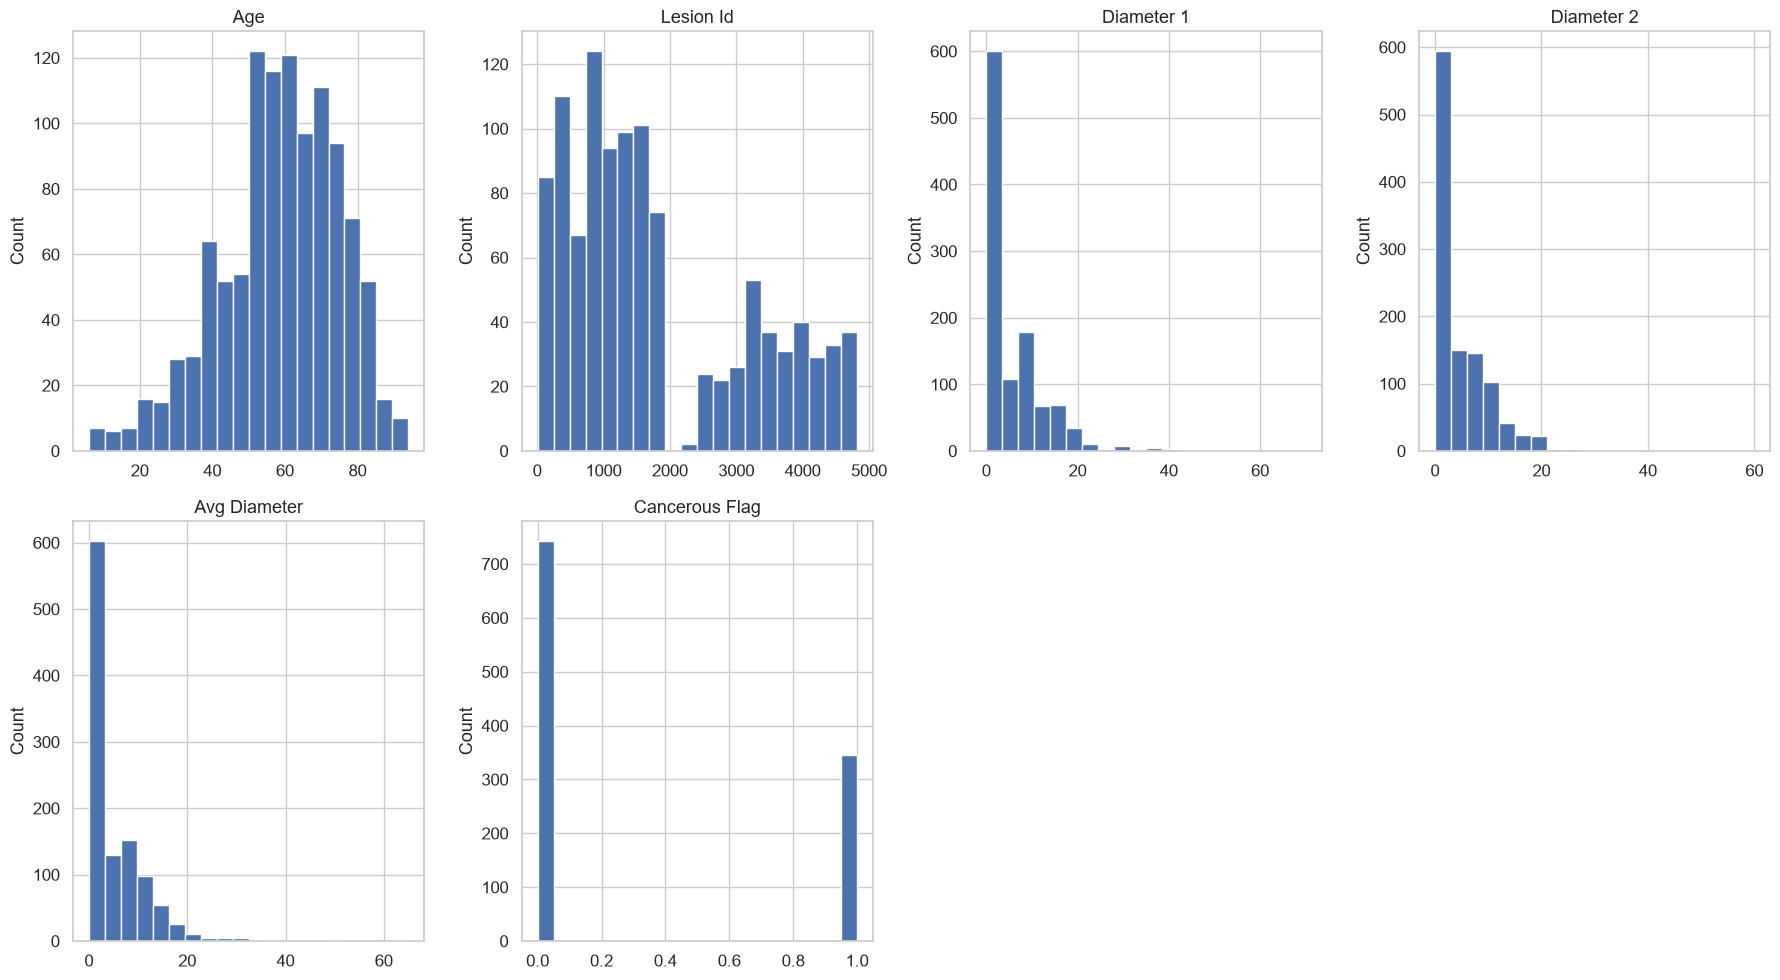

In [18]:
#step 6b - Histogram plot

# Whether variables follow approximately normal distributions.
# Variables showing positive or negative skewness.
#  Potential extreme values that may require further investigation.

fig, axes = plt.subplots(2, 4, figsize=(18,10))
axes = axes.flatten()

for ax, col in zip(axes, numerical_cols):
    ax.hist(df[col], bins=20)
    ax.set_title(col.replace("_", " ").title())
    ax.set_xlabel("")
    ax.set_ylabel("Count")

# Remove unused subplot
for ax in axes[len(numerical_cols):]:
    fig.delaxes(ax)

plt.tight_layout()
plt.show()

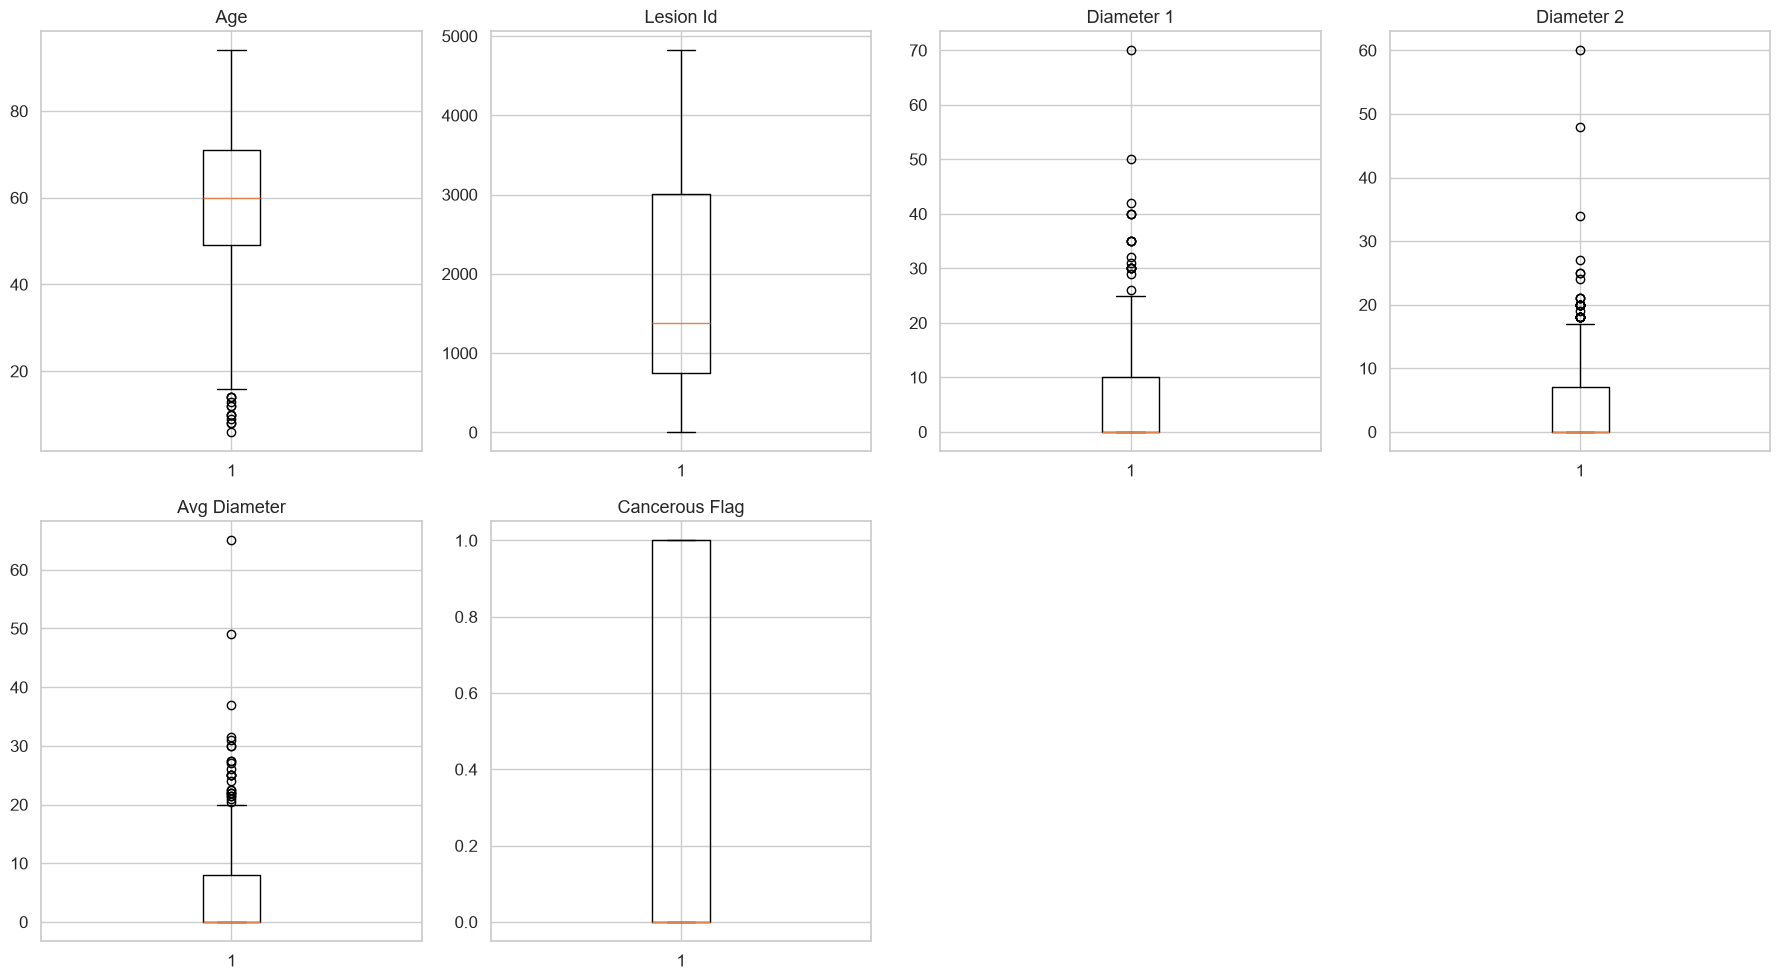

In [19]:
# step 6c - Boxplots (Outlier Detection)

fig, axes = plt.subplots(2,4, figsize=(18,10))
axes = axes.flatten()

for ax, col in zip(axes, numerical_cols):
    ax.boxplot(df[col], vert=True)
    ax.set_title(col.replace("_"," ").title())

for ax in axes[len(numerical_cols):]:
    fig.delaxes(ax)

plt.tight_layout()
plt.show()


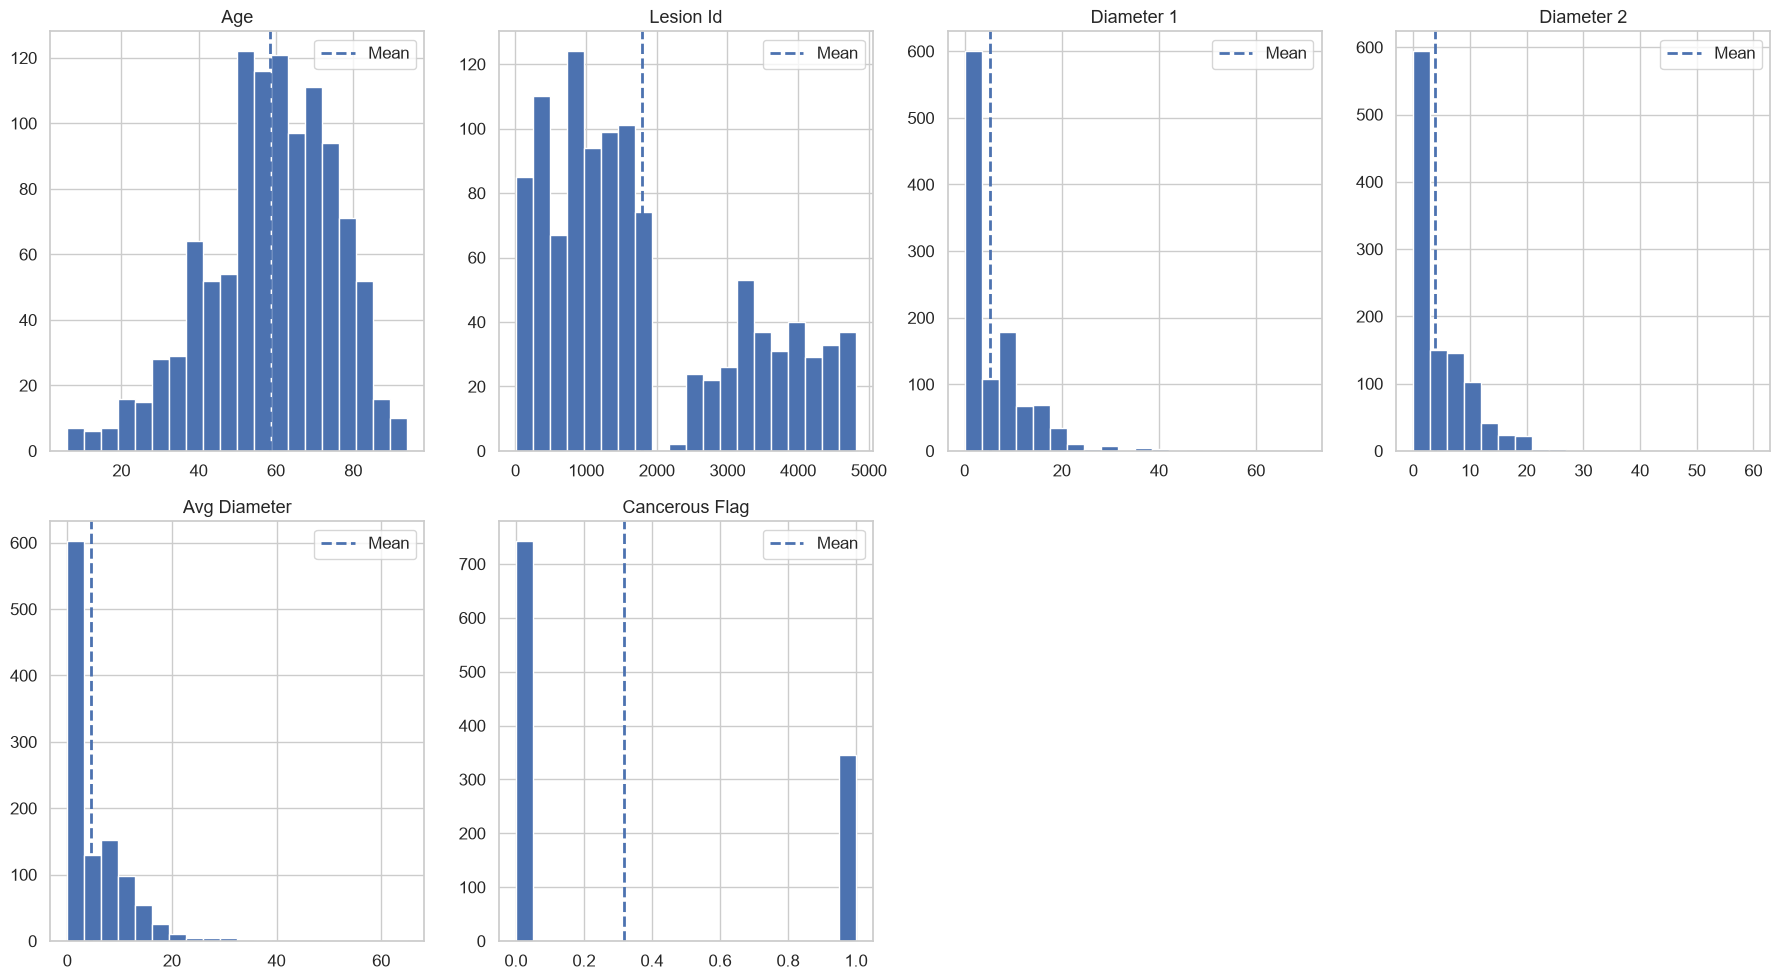

In [20]:
# step 6d - Distribution with Mean

fig, axes = plt.subplots(2,4, figsize=(18,10))
axes = axes.flatten()

for ax, col in zip(axes, numerical_cols):
    ax.hist(df[col], bins=20)

    ax.axvline(
        df[col].mean(),
        linestyle="--",
        linewidth=2,
        label="Mean"
    )

    ax.legend()
    ax.set_title(col.replace("_"," ").title())

for ax in axes[len(numerical_cols):]:
    fig.delaxes(ax)

plt.tight_layout()

In [21]:
# step 6e -  Skewness
skewness = (
    df[numerical_cols]
    .skew()
    .sort_values(ascending=False)
    .to_frame("Skewness")
)

display(skewness)

,Skewness
diameter_2,2.487147
avg_diameter,2.255599
diameter_1,2.206381
cancerous_flag,0.782627
lesion_id,0.725645
age,-0.519947


### Numerical Variable Summary

- The numerical analysis provides insight into the distribution, variability, and skewness of - - continuous features.

- Variables exhibiting strong skewness or substantial outliers may require transformation or robust 
scaling during preprocessing.

- These findings will guide feature engineering and model preparation in the next stage.

### STEP 7 — Categorical Variables
- Understand category frequencies.
- Identify dominant and rare categories.
- Explore class balance.
- Generate clinical insights from the distribution of each variable.

In [22]:
# step 7a -Identify Categorical Variables
categorical_cols = df.select_dtypes(exclude="number").columns.tolist()

print(f"Categorical columns ({len(categorical_cols)}):")
categorical_cols

Categorical columns (24):


['patient_id',
 'age_group',
 'gender',
 'smoke',
 'drink',
 'pesticide',
 'skin_cancer_history',
 'cancer_history',
 'has_piped_water',
 'has_sewage_system',
 'background_father',
 'background_mother',
 'fitspatrick',
 'region',
 'lesion_size_category',
 'itch',
 'grew',
 'hurt',
 'changed',
 'bleed',
 'elevation',
 'biopsed',
 'diagnostic',
 'cancer_status']

In [23]:
# step 7b - Frequency Tables
for col in categorical_cols:
    print("=" * 60)
    print(col.upper())
    print(df[col].value_counts())
    print()

PATIENT_ID
patient_id
PAT_100     1
PAT_1000    1
PAT_1006    1
PAT_1008    1
PAT_101     1
           ..
PAT_995     1
PAT_996     1
PAT_997     1
PAT_998     1
PAT_999     1
Name: count, Length: 1088, dtype: int64

AGE_GROUP
age_group
Older Adult    513
Elderly        297
Middle Age     221
Young Adult     57
Name: count, dtype: int64

GENDER
gender
MALE      726
FEMALE    362
Name: count, dtype: int64

SMOKE
smoke
No     1026
Yes      62
Name: count, dtype: int64

DRINK
drink
No     950
Yes    138
Name: count, dtype: int64

PESTICIDE
pesticide
No     865
Yes    223
Name: count, dtype: int64

SKIN_CANCER_HISTORY
skin_cancer_history
No     864
Yes    224
Name: count, dtype: int64

CANCER_HISTORY
cancer_history
No     816
Yes    272
Name: count, dtype: int64

HAS_PIPED_WATER
has_piped_water
No     782
Yes    306
Name: count, dtype: int64

HAS_SEWAGE_SYSTEM
has_sewage_system
No     815
Yes    273
Name: count, dtype: int64

BACKGROUND_FATHER
background_father
UNKNOWN        584
POMERANIA

### STEP 8 - Demographic Variables

In [24]:
demographic_cols = [
    "gender",
    "age_group",
    "background_father",
    "background_mother",
    "has_piped_water",
    "has_sewage_system"
]

# Keep only columns that exist
demographic_cols = [
    col for col in demographic_cols
    if col in df.columns
]

print(demographic_cols)


['gender', 'age_group', 'background_father', 'background_mother', 'has_piped_water', 'has_sewage_system']


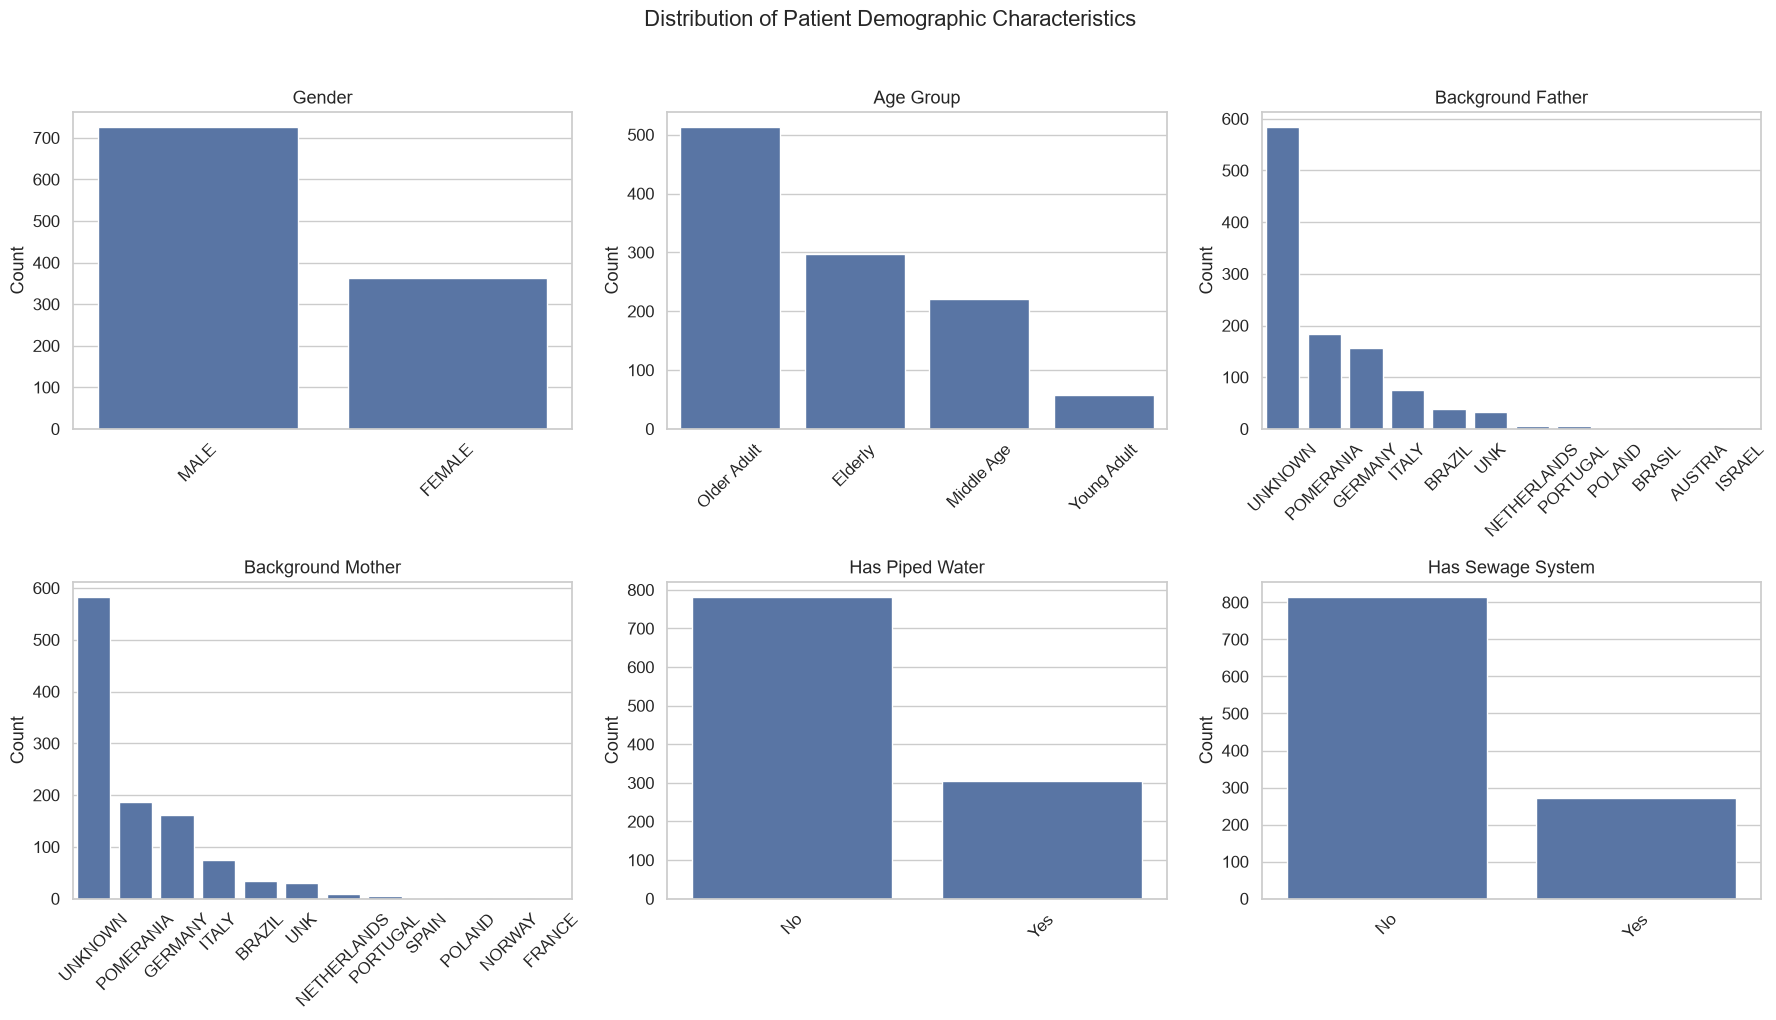

In [25]:
# step 8b - plot the distribution of demography

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for ax, col in zip(axes, demographic_cols):
    order = df[col].value_counts().index

    sns.countplot(
        data=df,
        x=col,
        order=order,
        ax=ax
    )

    ax.set_title(col.replace("_", " ").title())
    ax.set_xlabel("")
    ax.set_ylabel("Count")
    ax.tick_params(axis="x", rotation=45)

for ax in axes[len(demographic_cols):]:
    fig.delaxes(ax)

plt.suptitle(
    "Distribution of Patient Demographic Characteristics",
    fontsize=16,
    y=1.02
)

plt.tight_layout()
plt.show()

### STEP 9 - Behavioural and Environmental Risk Factors

In [26]:

behavioural_cols = [
    "smoke",
    "drink",
    "pesticide"
]

behavioural_cols = [
    col for col in behavioural_cols
    if col in df.columns
]

print(behavioural_cols)



['smoke', 'drink', 'pesticide']


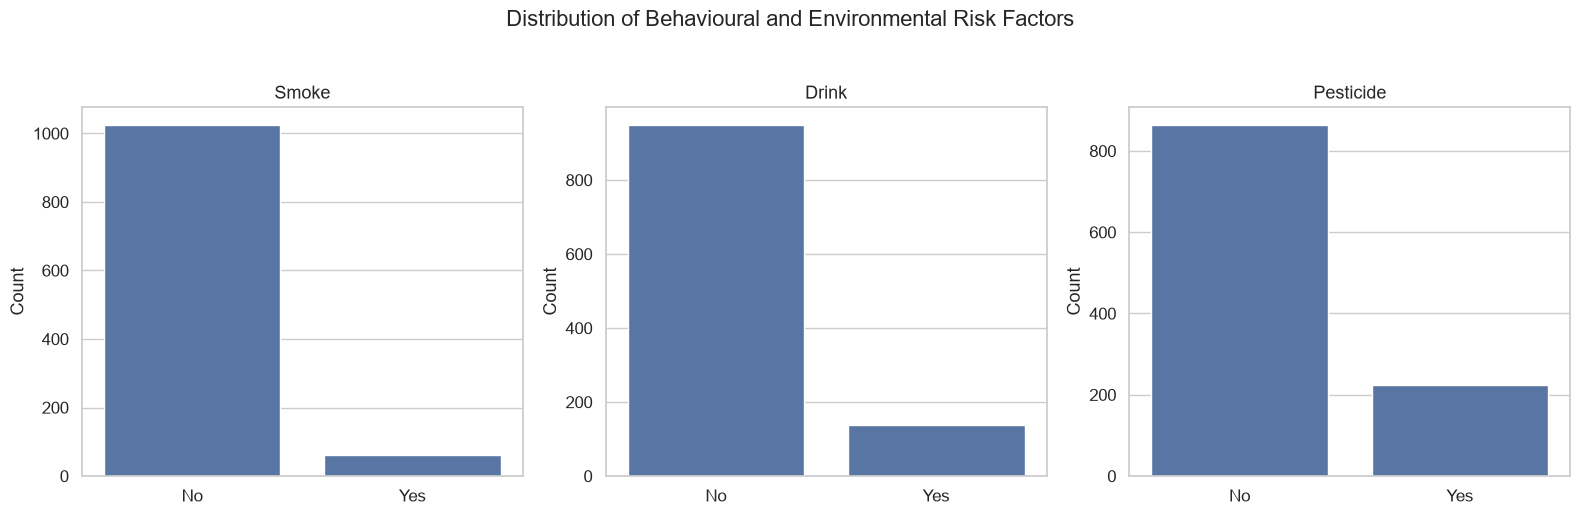

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
axes = np.array(axes).flatten()

for ax, col in zip(axes, behavioural_cols):
    order = df[col].value_counts().index

    sns.countplot(
        data=df,
        x=col,
        order=order,
        ax=ax
    )

    ax.set_title(col.replace("_", " ").title())
    ax.set_xlabel("")
    ax.set_ylabel("Count")

for ax in axes[len(behavioural_cols):]:
    fig.delaxes(ax)

plt.suptitle(
    "Distribution of Behavioural and Environmental Risk Factors",
    fontsize=16,
    y=1.03
)

plt.tight_layout()
plt.show()

### STEP 10 — Clinical and Lesion Risk Characteristics

In [28]:
clinical_cols = [
    "skin_cancer_history",
    "cancer_history",
    "itch",
    "grew",
    "hurt",
    "changed",
    "bleed",
    "elevation",
    "biopsed",
    "fitspatrick",
    "lesion_size_category"
]

clinical_cols = [
    col for col in clinical_cols
    if col in df.columns
]

print(clinical_cols)

['skin_cancer_history', 'cancer_history', 'itch', 'grew', 'hurt', 'changed', 'bleed', 'elevation', 'biopsed', 'fitspatrick', 'lesion_size_category']


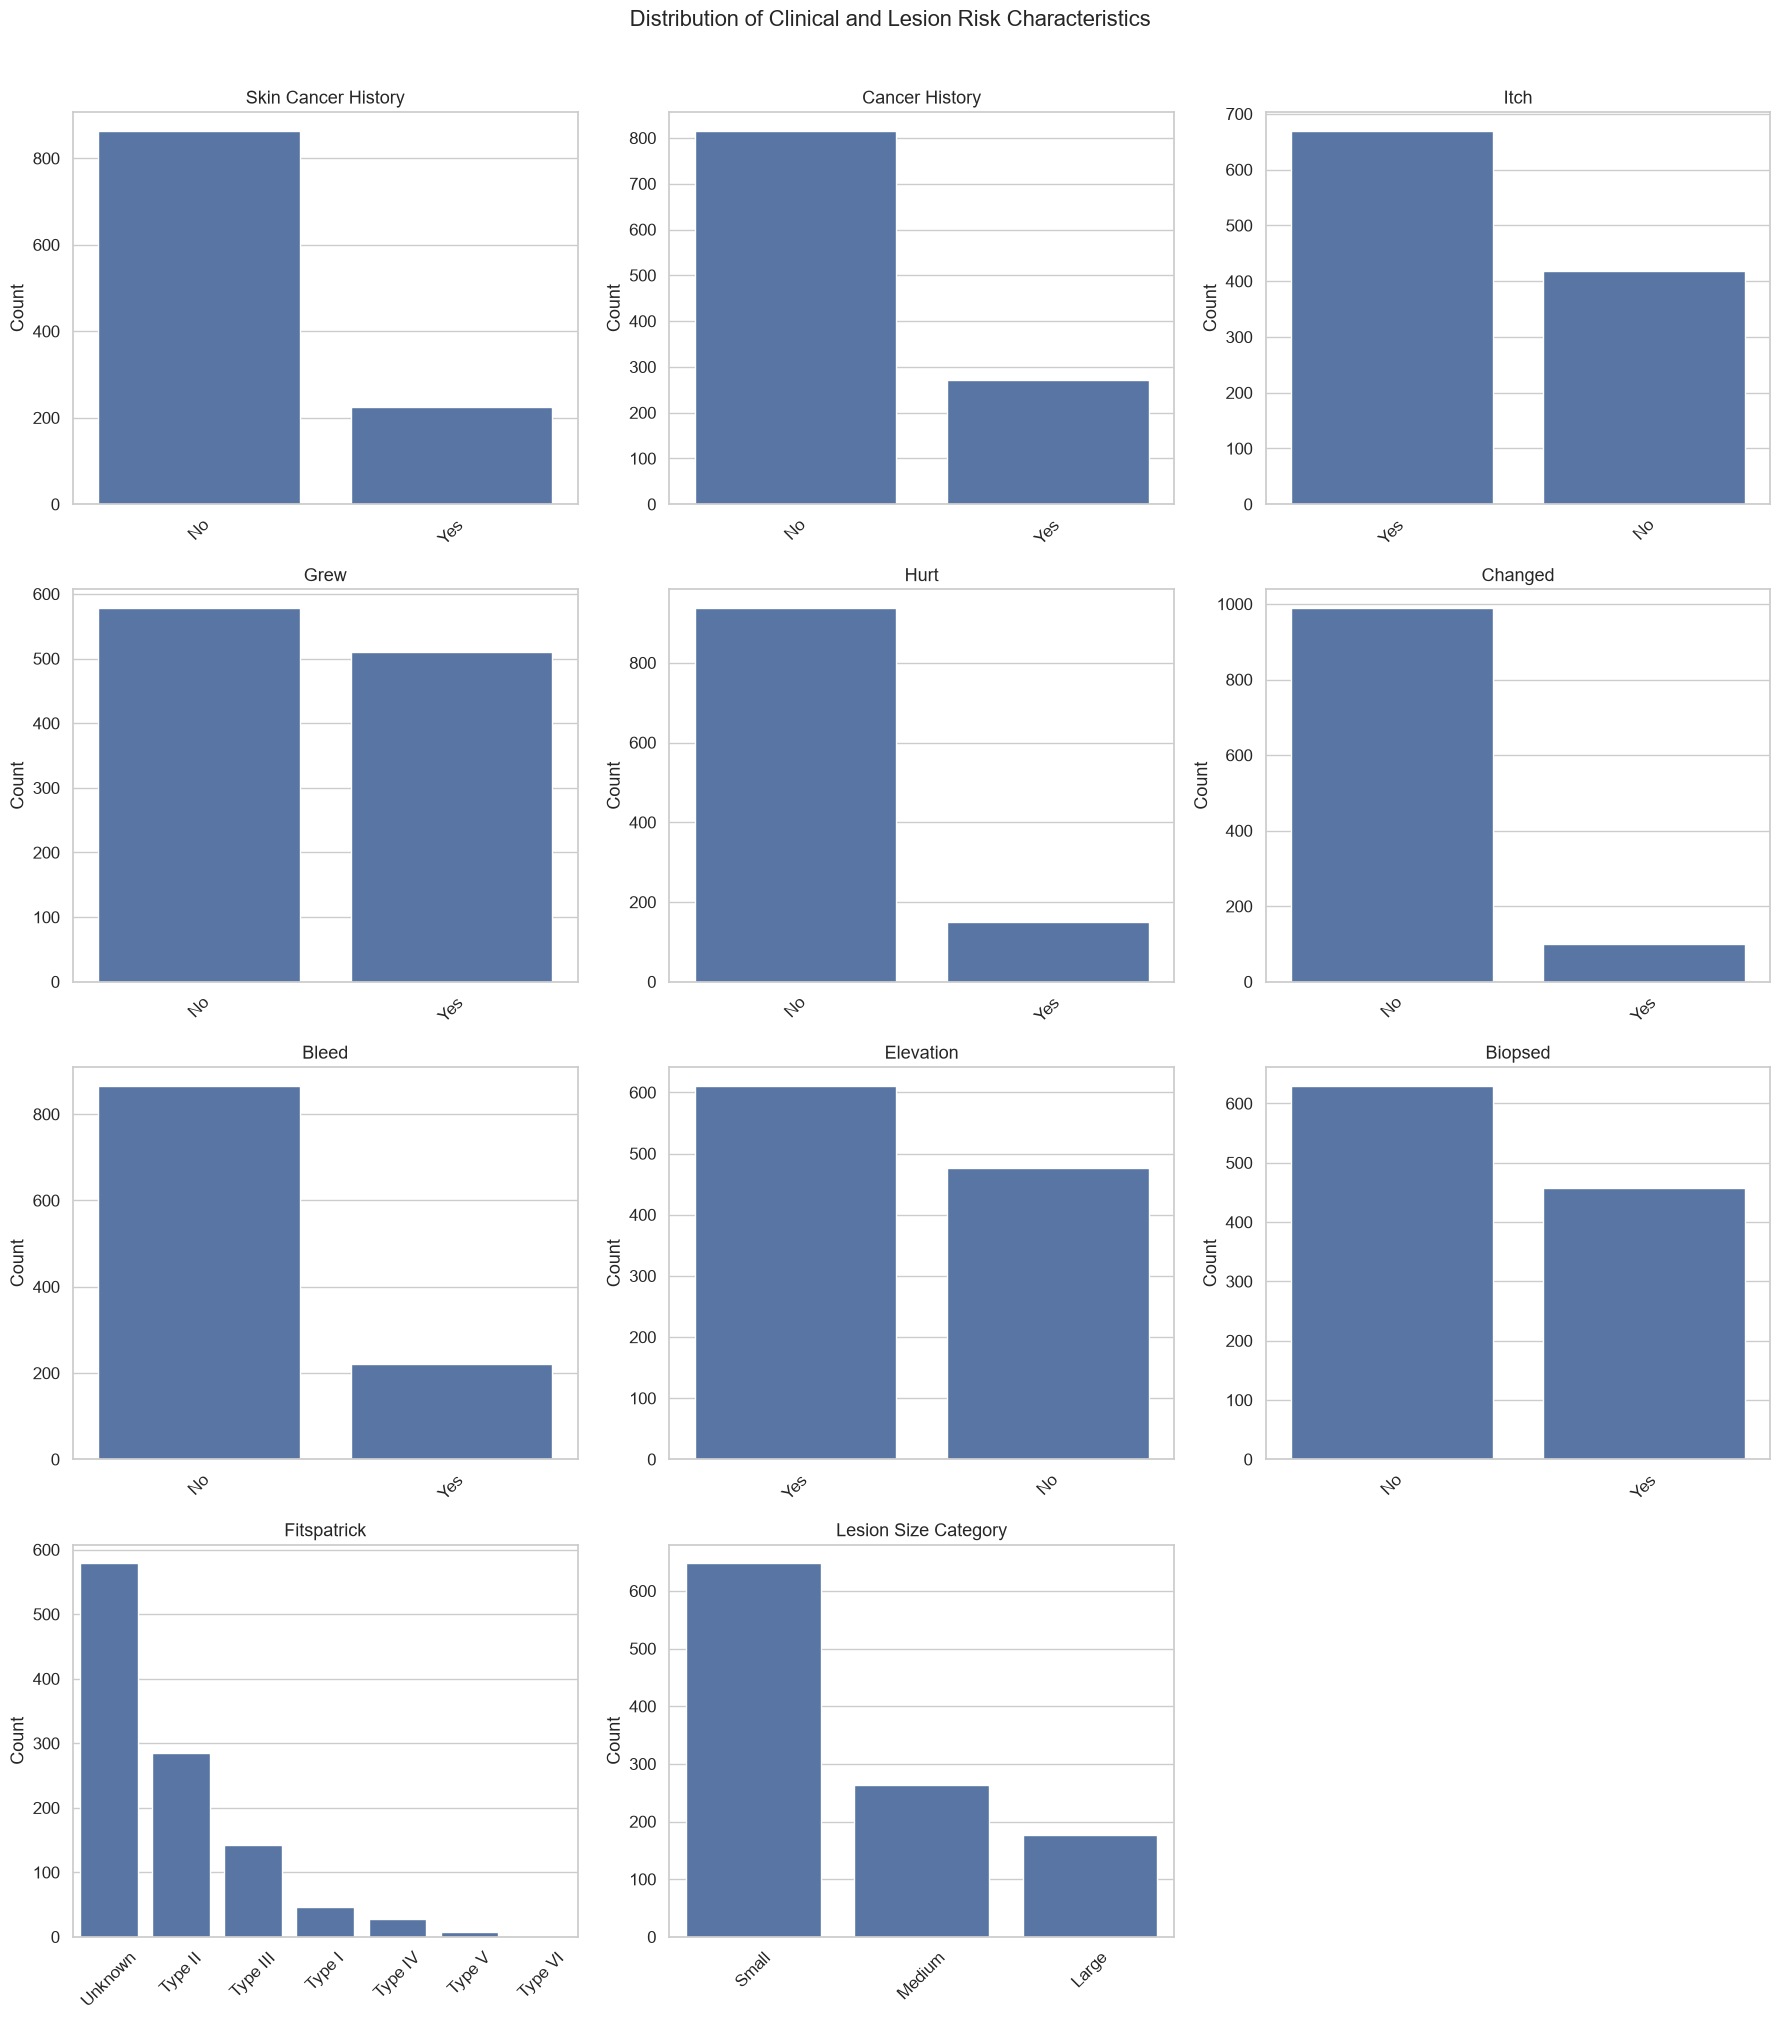

In [29]:
n_cols = 3
n_rows = int(np.ceil(len(clinical_cols) / n_cols))

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(18, 5 * n_rows)
)

axes = np.array(axes).flatten()

for ax, col in zip(axes, clinical_cols):
    order = df[col].value_counts().index

    sns.countplot(
        data=df,
        x=col,
        order=order,
        ax=ax
    )

    ax.set_title(col.replace("_", " ").title())
    ax.set_xlabel("")
    ax.set_ylabel("Count")
    ax.tick_params(axis="x", rotation=45)

for ax in axes[len(clinical_cols):]:
    fig.delaxes(ax)

plt.suptitle(
    "Distribution of Clinical and Lesion Risk Characteristics",
    fontsize=16,
    y=1.01
)

plt.tight_layout()
plt.show()

### STEP 11 -  Diagnosis and Target Distribution

In [30]:
diagnosis_cols = [
    "diagnostic",
    "cancerous_flag"
]

diagnosis_cols = [
    col for col in diagnosis_cols
    if col in df.columns
]

print(diagnosis_cols)


['diagnostic', 'cancerous_flag']


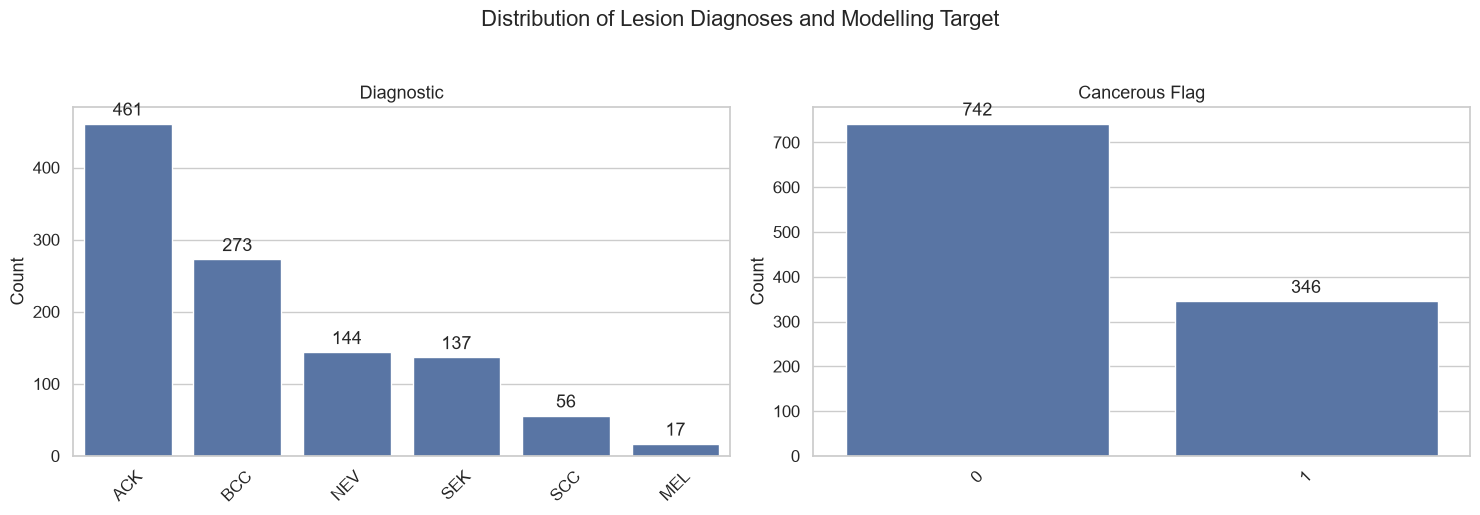

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes = np.array(axes).flatten()

for ax, col in zip(axes, diagnosis_cols):
    order = df[col].value_counts().index

    sns.countplot(
        data=df,
        x=col,
        order=order,
        ax=ax
    )

    ax.set_title(col.replace("_", " ").title())
    ax.set_xlabel("")
    ax.set_ylabel("Count")
    ax.tick_params(axis="x", rotation=45)

    # Add count labels
    for container in ax.containers:
        ax.bar_label(container, padding=3)

for ax in axes[len(diagnosis_cols):]:
    fig.delaxes(ax)

plt.suptitle(
    "Distribution of Lesion Diagnoses and Modelling Target",
    fontsize=16,
    y=1.03
)

plt.tight_layout()
plt.show()

### Diagnosis and Target Insights

The cancerous flag displays the modelling target:

- `0` represents benign lesions.
- `1` represents malignant lesions.

- The target distribution show class-imbalance handling may be needed during model development

- The `diagnostic` variable will be retained for EDA but removed before modelling because the target - was derived from it, making it a source of target leakage.


### STEP 12 — Bivariate Analysis

- Examine relationships between numerical variables.
- Assess how numerical features vary across categories.
- Investigate associations between categorical variables.
- Identify patterns associated with malignant skin lesions.


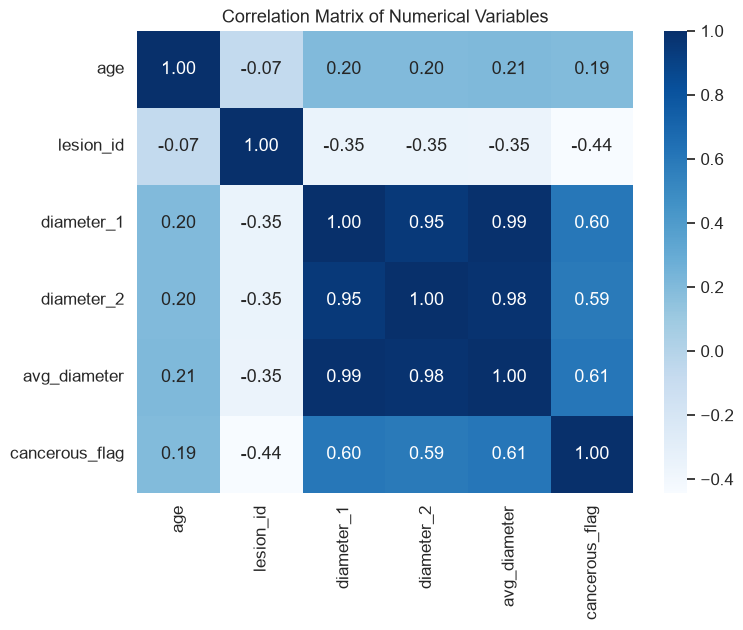

In [32]:
# step 12a(i) - Numerical vs Numerical

# Correlation Matrix
corr = df[numerical_cols].corr()

plt.figure(figsize=(8,6))

sns.heatmap(
    corr,
    annot=True,
    cmap="Blues",
    fmt=".2f"
)

plt.title("Correlation Matrix of Numerical Variables")

plt.show()


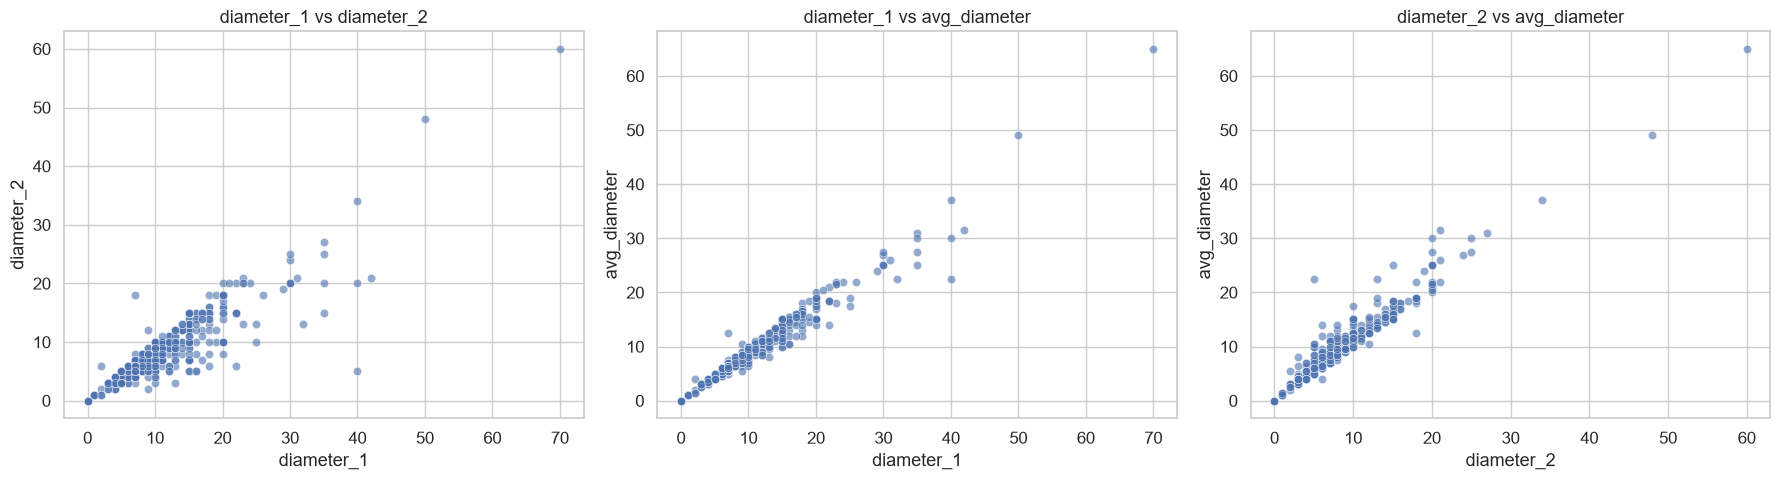

In [33]:
# step 12a(ii) - Scatterplots

scatter_pairs = [
    ("diameter_1", "diameter_2"),
    ("diameter_1", "avg_diameter"),
    ("diameter_2", "avg_diameter")
]
fig, axes = plt.subplots(1,3, figsize=(18,5))

for ax, (x, y) in zip(axes, scatter_pairs):

    sns.scatterplot(
        data=df,
        x=x,
        y=y,
        alpha=0.6,
        ax=ax
    )

    ax.set_title(f"{x} vs {y}")

plt.tight_layout()
plt.show()

### STEP 12B — Numerical vs Categorical


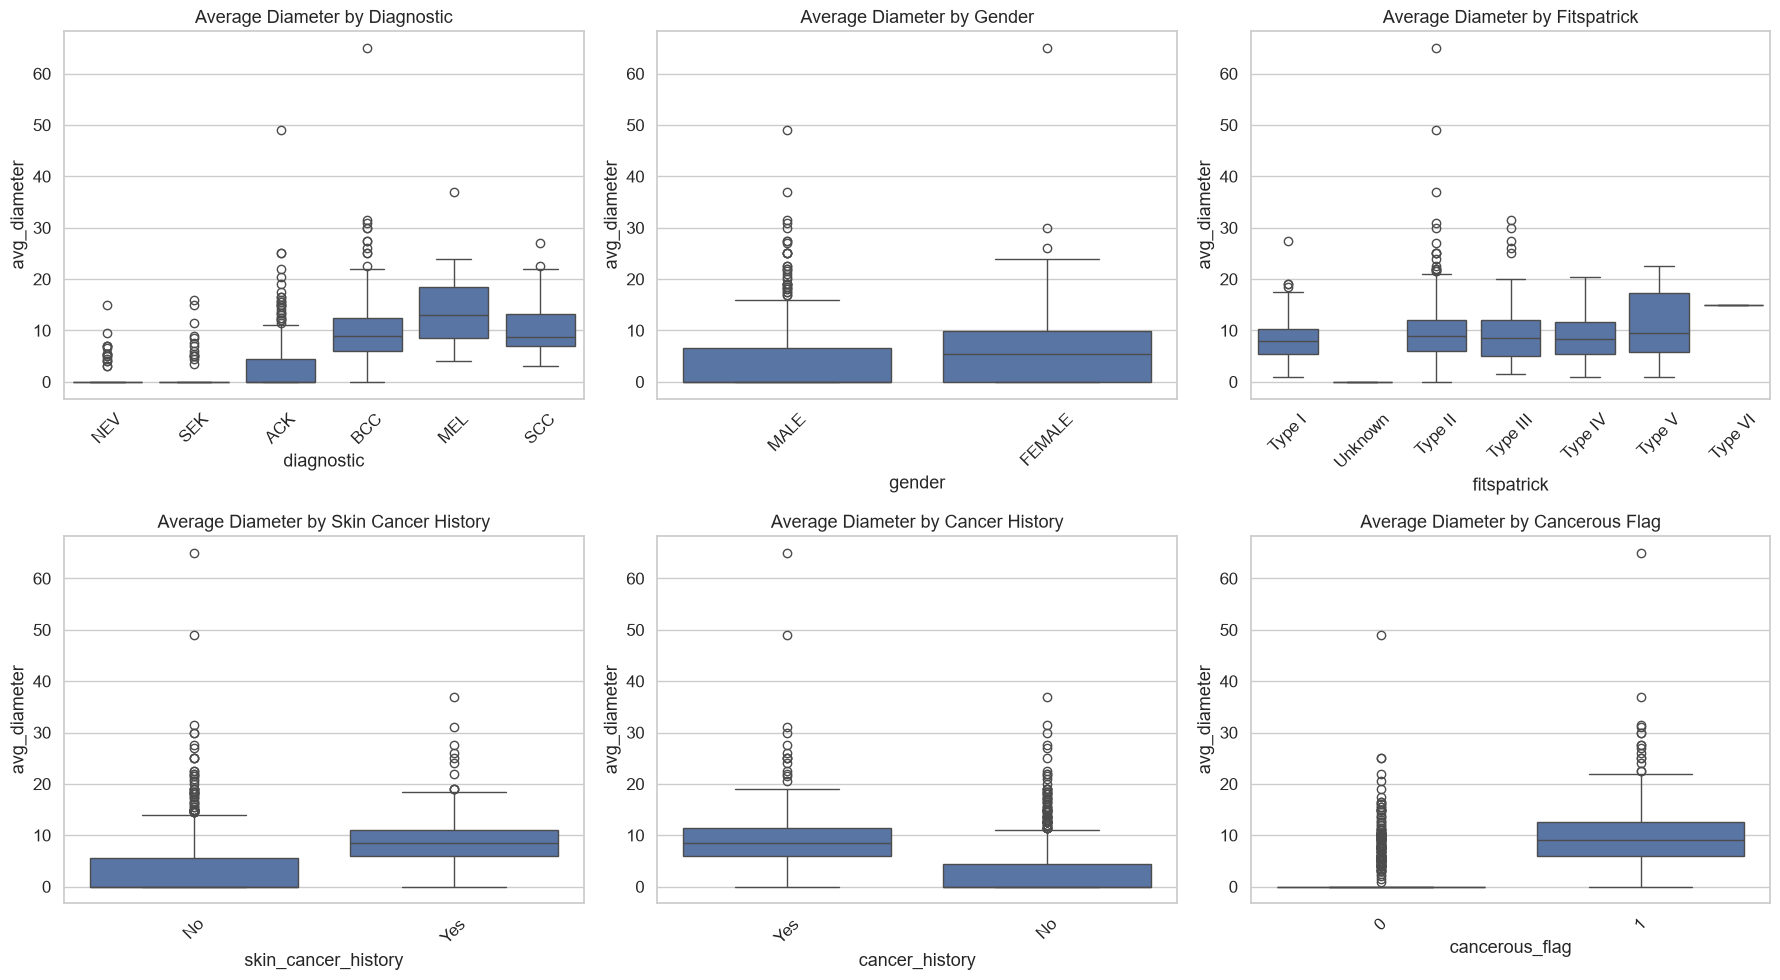

In [34]:
# step 12b(i) - compare Average Lesion Diameter against several categorical variables using boxplots.

cat_cols = [
    "diagnostic",
    "gender",
    "fitspatrick",
    "skin_cancer_history",
    "cancer_history",
    "cancerous_flag"
]

cat_cols = [
    col for col in cat_cols
    if col in df.columns
]
fig, axes = plt.subplots(2,3, figsize=(18,10))
axes = axes.flatten()

for ax, col in zip(axes, cat_cols):

    sns.boxplot(
        data=df,
        x=col,
        y="avg_diameter",
        ax=ax
    )

    ax.set_title(f"Average Diameter by {col.replace('_',' ').title()}")
    ax.tick_params(axis="x", rotation=45)

for ax in axes[len(cat_cols):]:
    fig.delaxes(ax)

plt.tight_layout()
plt.show()

In [35]:
# step 12b(ii)Group Statistics
for col in cat_cols:

    print("="*60)

    print(col.upper())

    display(
        df.groupby(col)["avg_diameter"]
        .agg(["count","mean","median","std"])
        .round(2)
    )

DIAGNOSTIC


,count,mean,median,std
diagnostic,,,,
ACK,461,2.62,0.00,5.09
BCC,273,9.97,9.00,6.45
MEL,17,14.09,13.00,8.14
NEV,144,0.67,0.00,2.13
SCC,56,10.46,8.75,5.21
SEK,137,0.80,0.00,2.66


GENDER


,count,mean,median,std
gender,,,,
FEMALE,362,6.23,5.5,6.50
MALE,726,3.72,0.0,6.21


FITSPATRICK


...

,count,mean,median,std
skin_cancer_history,,,,
No,864,3.35,0.0,6.17
Yes,224,9.21,8.5,5.07


CANCER_HISTORY


,count,mean,median,std
cancer_history,,,,
No,816,2.87,0.0,5.42
Yes,272,9.62,8.5,6.52


CANCEROUS_FLAG


,count,mean,median,std
cancerous_flag,,,,
0,742,1.90,0.0,4.37
1,346,10.25,9.0,6.40


### Numerical vs Categorical Insights

- Boxplots demonstrate how lesion size varies across demographic, behavioural, and clinical categories.

- Group summary statistics complement the visualisations by quantifying differences in lesion size - - - across each subgroup.


### STEP 12C — Categorical vs Categorical Analysis

- Assess how demographic characteristics relate to the target outcome.
- Investigate behavioural and environmental risk factors.
- Explore clinical characteristics associated with malignant lesions.
- Identify patterns that may be useful for predictive modelling.

- Crosstabs, percentage tables, stacked bar charts, and heatmaps are used to compare categorical - - - - variables.

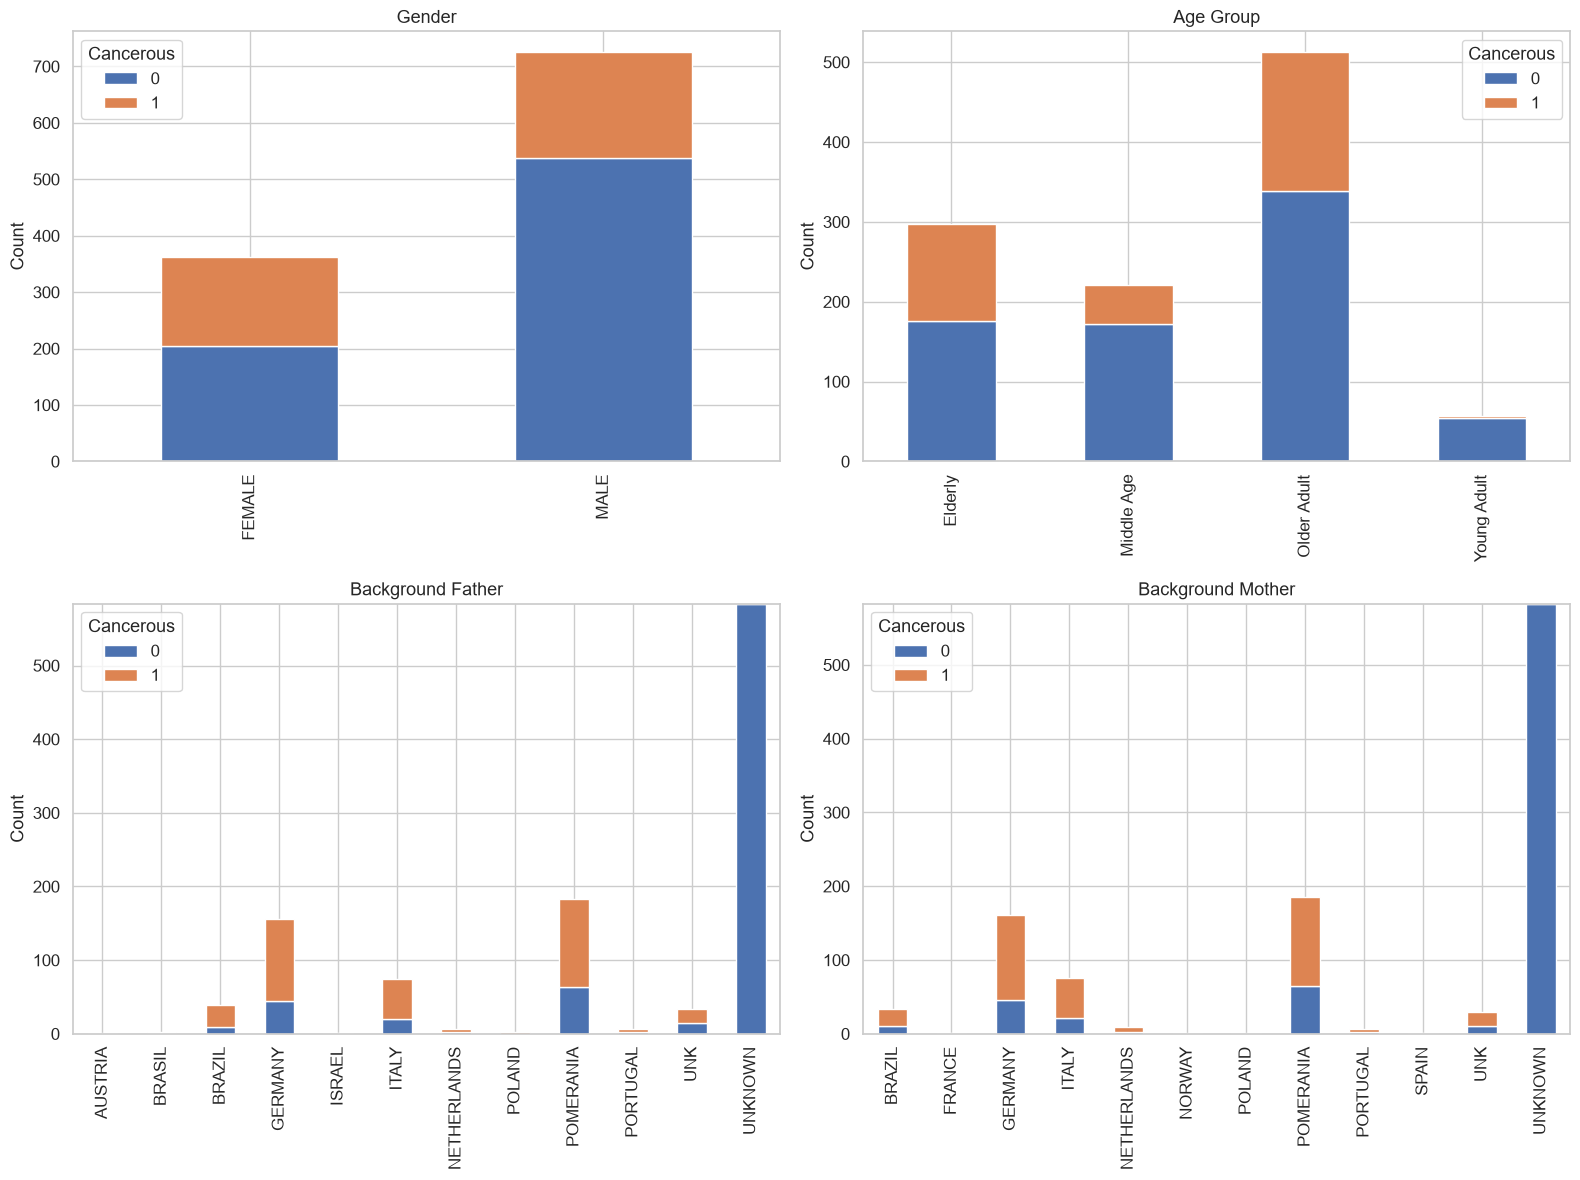

In [36]:
# step 12c(i) - Demographic Characteristics vs Cancer Status
demographic_cols = [
    "gender",
    "age_group",
    "background_father",
    "background_mother"
]

demographic_cols = [
    col for col in demographic_cols
    if col in df.columns
]
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

for ax, col in zip(axes, demographic_cols):

    crosstab = pd.crosstab(
        df[col],
        df["cancerous_flag"]
    )

    crosstab.plot(
        kind="bar",
        stacked=True,
        ax=ax
    )

    ax.set_title(col.replace("_"," ").title())
    ax.set_xlabel("")
    ax.set_ylabel("Count")
    ax.legend(title="Cancerous")

for ax in axes[len(demographic_cols):]:
    fig.delaxes(ax)

plt.tight_layout()
plt.show()

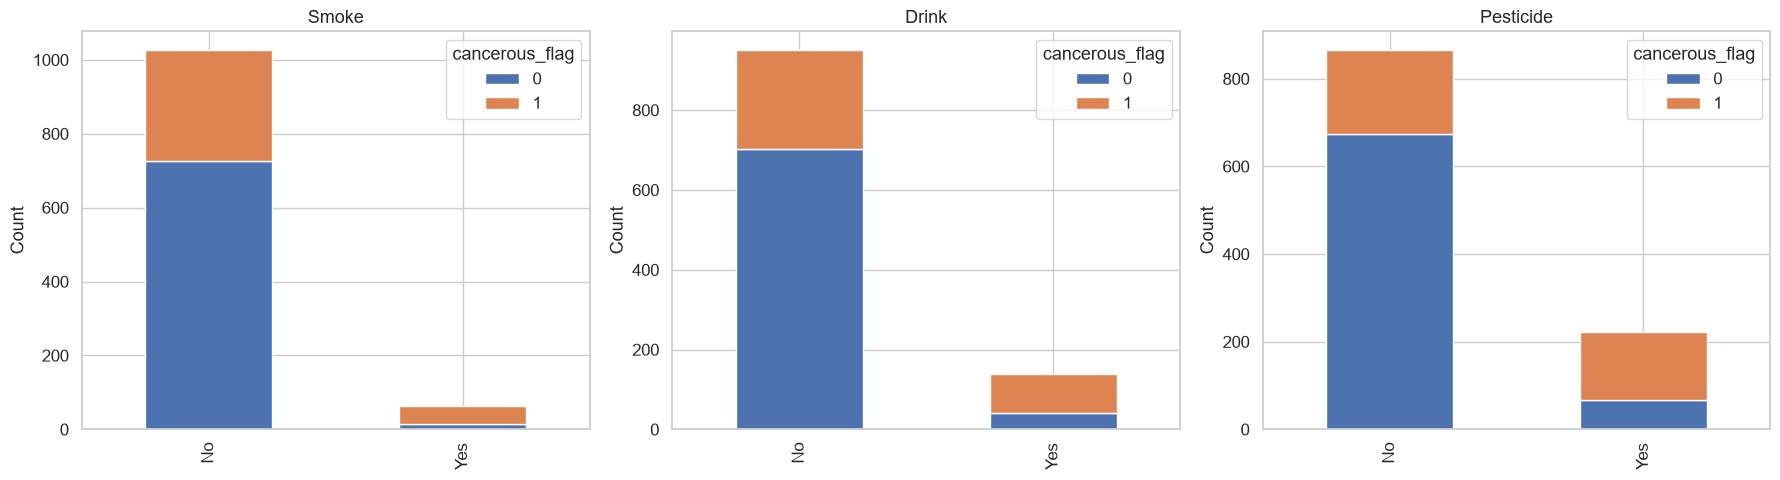

In [37]:
# step 12c(ii) - Behavioural & Environmental Risk Factors
behaviour_cols = [
    "smoke",
    "drink",
    "pesticide"
]

behaviour_cols = [
    col for col in behaviour_cols
    if col in df.columns
]
fig, axes = plt.subplots(1,3, figsize=(18,5))
axes = axes.flatten()

for ax, col in zip(axes, behaviour_cols):

    crosstab = pd.crosstab(
        df[col],
        df["cancerous_flag"]
    )

    crosstab.plot(
        kind="bar",
        stacked=True,
        ax=ax
    )

    ax.set_title(col.title())
    ax.set_xlabel("")
    ax.set_ylabel("Count")

plt.tight_layout()
plt.show()

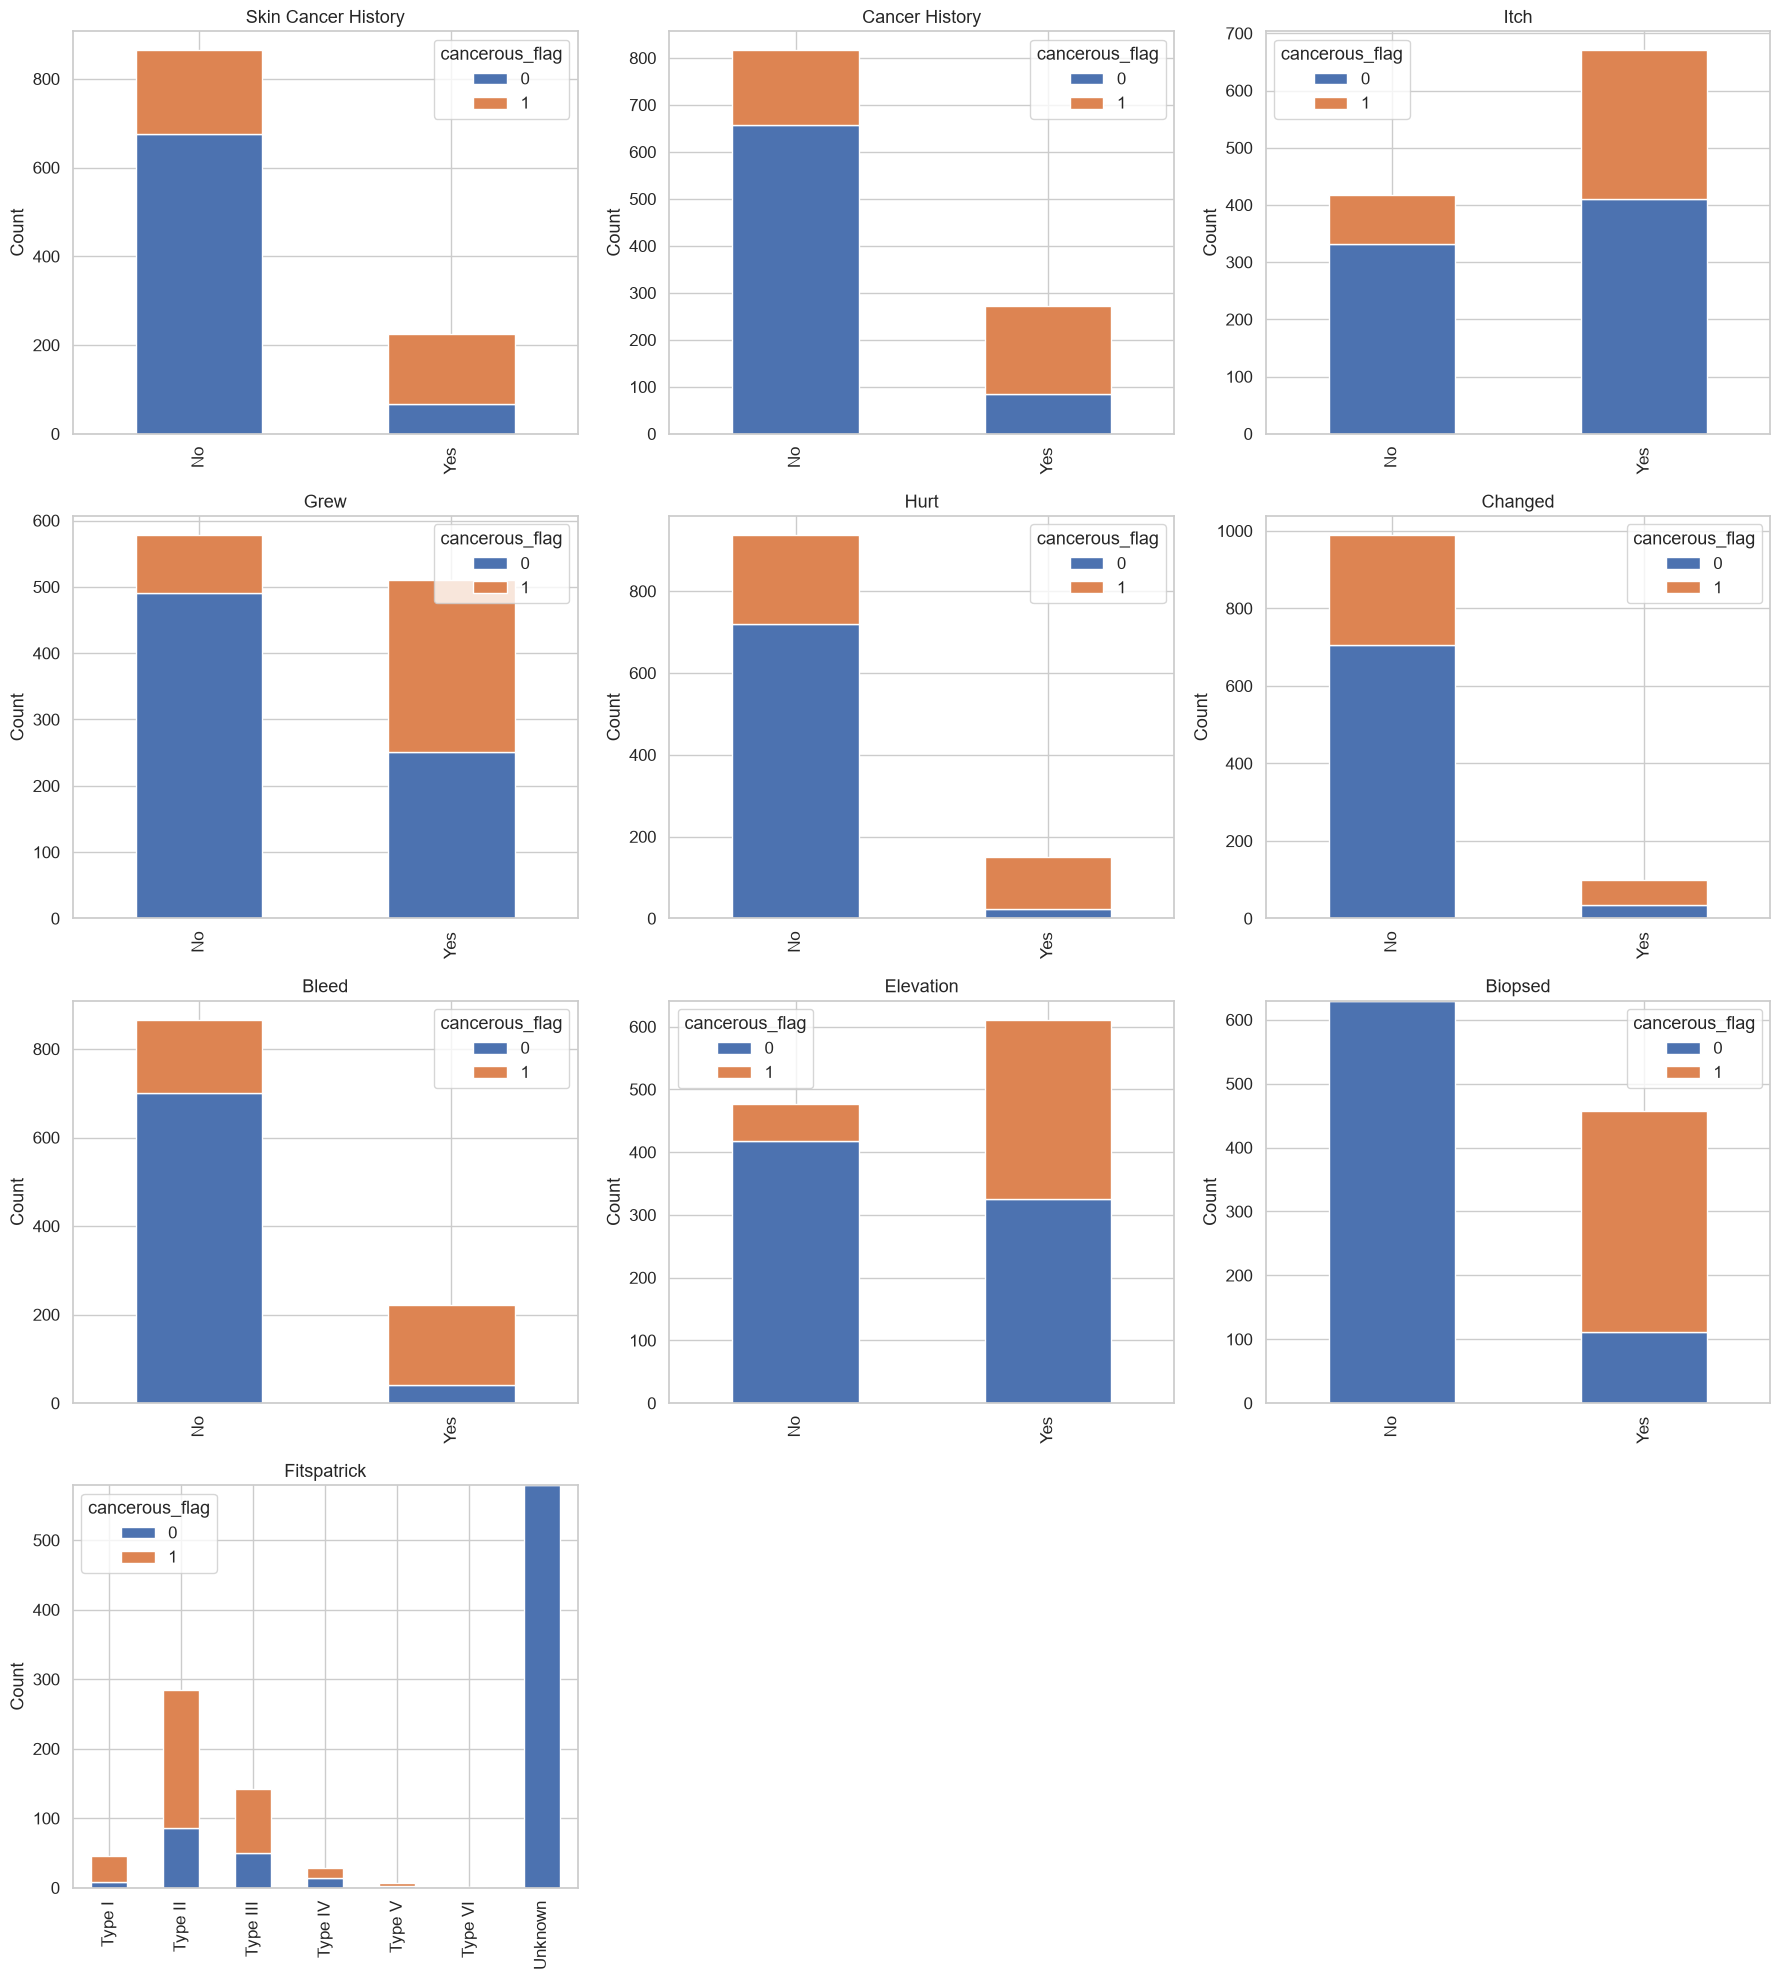

In [38]:
# step 12c(iii) - Clinical Characteristics
clinical_cols = [
    "skin_cancer_history",
    "cancer_history",
    "itch",
    "grew",
    "hurt",
    "changed",
    "bleed",
    "elevation",
    "biopsed",
    "fitspatrick"
]

clinical_cols = [
    col for col in clinical_cols
    if col in df.columns
]
n_cols = 3
n_rows = int(np.ceil(len(clinical_cols) / n_cols))

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(18, 5*n_rows)
)

axes = axes.flatten()

for ax, col in zip(axes, clinical_cols):

    crosstab = pd.crosstab(
        df[col],
        df["cancerous_flag"]
    )

    crosstab.plot(
        kind="bar",
        stacked=True,
        ax=ax
    )

    ax.set_title(col.replace("_"," ").title())
    ax.set_xlabel("")
    ax.set_ylabel("Count")

for ax in axes[len(clinical_cols):]:
    fig.delaxes(ax)

plt.tight_layout()
plt.show()

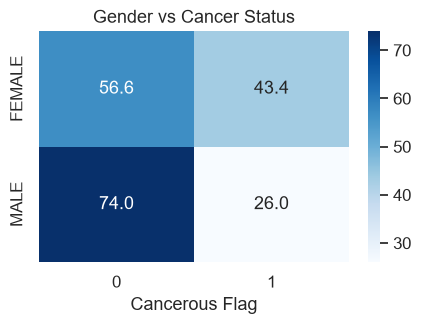

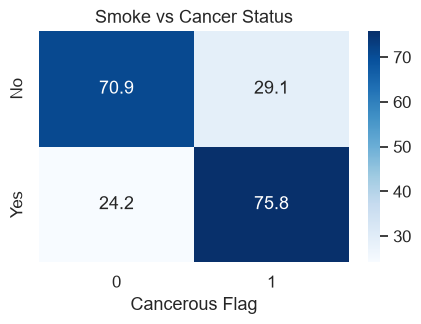

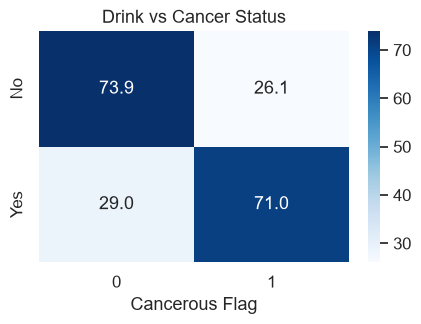

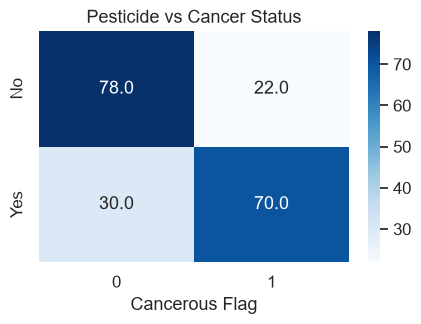

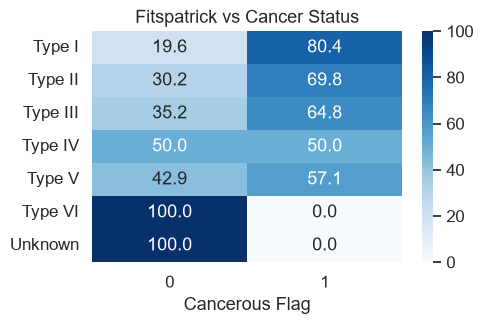

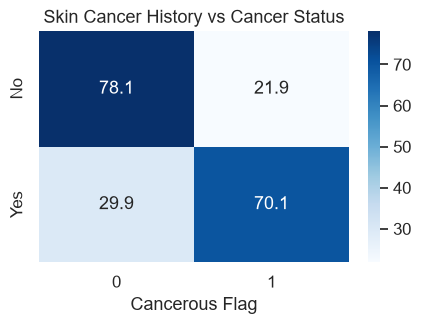

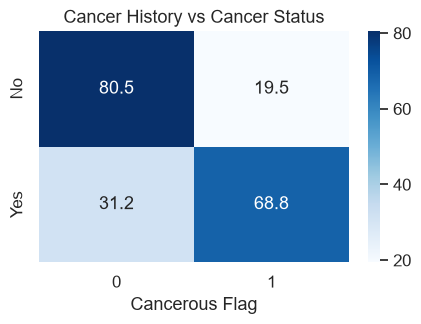

In [39]:
#step 12c(iv) - Heatmaps (Percentage Crosstabs)

heatmap_cols = [
    "gender",
    "smoke",
    "drink",
    "pesticide",
    "fitspatrick",
    "skin_cancer_history",
    "cancer_history"
]

heatmap_cols = [
    col for col in heatmap_cols
    if col in df.columns
]
for col in heatmap_cols:

    plt.figure(figsize=(5,3))

    table = pd.crosstab(
        df[col],
        df["cancerous_flag"],
        normalize="index"
    ) * 100

    sns.heatmap(
        table,
        annot=True,
        fmt=".1f",
        cmap="Blues"
    )

    plt.title(
        f"{col.replace('_',' ').title()} vs Cancer Status"
    )

    plt.ylabel("")
    plt.xlabel("Cancerous Flag")

    plt.show()

### Categorical Relationship Summary

- The categorical analysis highlights relationships between demographic, behavioural, environmental, -  and clinical factors and the target variable.

- Percentage heatmaps make it easier to identify groups with relatively higher proportions of malignant lesions.


### STEP 13 — Exploratory Data Analysis Summary


### Dataset Overview
- The dataset contains **1,088 observations** and **29 variables**.
- Features include demographic characteristics, behavioural risk factors, clinical information, lesion measurements, and diagnostic outcomes.

### Data Quality
- No missing values were identified.
- No duplicate records were found.
- Patient identifiers were unique.
- Duplicate lesion identifiers were observed and retained for further investigation.

### Numerical Variables
- Lesion diameter measurements exhibited positive skewness and several potential outliers.
- Strong positive correlations were observed between lesion measurement variables, indicating possible redundancy.

### Demographic Characteristics
- The dataset included representation across multiple age groups and both genders.
- Household infrastructure and parental background variables showed varying distributions across the study population.

### Behavioural and Environmental Risk Factors
- Smoking, alcohol consumption, and pesticide exposure varied across participants.
- Behavioural risk factors showed differing proportions of malignant lesions.

### Clinical Characteristics
- Clinical symptoms, previous cancer history, biopsy status, Fitzpatrick skin type, and lesion size varied across patients.
- Several clinical variables demonstrated noticeable differences between benign and malignant lesions.

### Target Variable
- Approximately one-third of lesions were malignant.
- The target distribution indicates moderate class imbalance, which will be addressed during model development.

